# 03 · Binary Brain Storm Optimization for attribute selection

Phase 3 of the reimplementation of Indian Patent No. 601763. The patent selects features with Binary Brain Storm Optimization (BBSO), a population metaheuristic that maximises F1 and stops when consecutive iterations bring no improvement.

**How it is set up here**

- One *idea* is a 0/1 mask over the **13 clinical attributes**. A one-hot attribute such as `cp` is kept or dropped with all four of its encoded columns (`columns_for_attributes`), so the search space is 2¹³ masks, never the 22 columns.
- **Fitness** = macro F1 of logistic regression under an inner 3-fold stratified CV on the *training split only*. Preprocessing is fitted per inner fold, once, and reused for every mask (it is attribute-wise, so this is leakage-free and fast). Fitness is cached per mask and the cache is shared across seeds.
- **Search**: 20 ideas, k-means into 3 clusters, new ideas from a cluster centre, a random member, or a merge of two clusters, plus Gaussian step noise that shrinks over iterations; a sigmoid transfer turns positions into bits; greedy replacement. Early stopping after 12 iterations without improvement, 50 at most.
- **Ten seeds**, then per-attribute selection frequency and a chosen subset: the most frequent best mask (falling back to a ≥ 50% consensus if no mask repeats).

Everything below is read from `results/03_*` written by `scripts/phase3_bbso.py`; the search itself is not re-run in this notebook.

In [1]:
import sys, json
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
from IPython.display import Image

from hfm import config

pd.set_option("display.width", 130)
R = "../results/"
runtime = json.load(open(R + "03_runtime.json"))
runs = pd.read_csv(R + "03_bbso_runs.csv")
runs

,seed,best_macro_f1,n_iter,stopped_early,n_selected,selected,seconds
0,0,0.639725,36,True,10,age trestbps thalch oldpeak ca cp restecg exan...,15.5
1,1,0.638209,23,True,10,age chol thalch oldpeak ca sex cp restecg slop...,8.5
2,2,0.631703,15,True,8,age trestbps thalch ca cp exang slope thal,5.7
3,3,0.639725,25,True,10,age trestbps thalch oldpeak ca cp restecg exan...,8.0
4,4,0.639725,36,True,10,age trestbps thalch oldpeak ca cp restecg exan...,10.5
5,5,0.639725,26,True,10,age trestbps thalch oldpeak ca cp restecg exan...,7.2
6,6,0.639725,26,True,10,age trestbps thalch oldpeak ca cp restecg exan...,6.7
7,7,0.639725,33,True,10,age trestbps thalch oldpeak ca cp restecg exan...,8.4
8,8,0.634560,25,True,11,age trestbps chol thalch oldpeak ca sex cp res...,6.6
9,9,0.639725,18,True,10,age trestbps thalch oldpeak ca cp restecg exan...,4.1


## 1. What the ten seeds found

In [2]:
print("chosen subset:", runtime["chosen_subset"])
print("chosen by:    ", runtime["chosen_by"])
print(f"BBSO wall-clock: {runtime['bbso_total_s']} s for 10 seeds; evaluation: {runtime['evaluation_s']} s")
print(f"fitness calls: {runtime['fitness_calls']}, unique masks actually scored: {runtime['unique_masks_evaluated']}")

chosen subset: ['age', 'trestbps', 'thalch', 'oldpeak', 'ca', 'cp', 'restecg', 'exang', 'slope', 'thal']
chosen by:     modal best mask (7 of 10 seeds)
BBSO wall-clock: 81.2 s for 10 seeds; evaluation: 8.1 s
fitness calls: 5460, unique masks actually scored: 2720


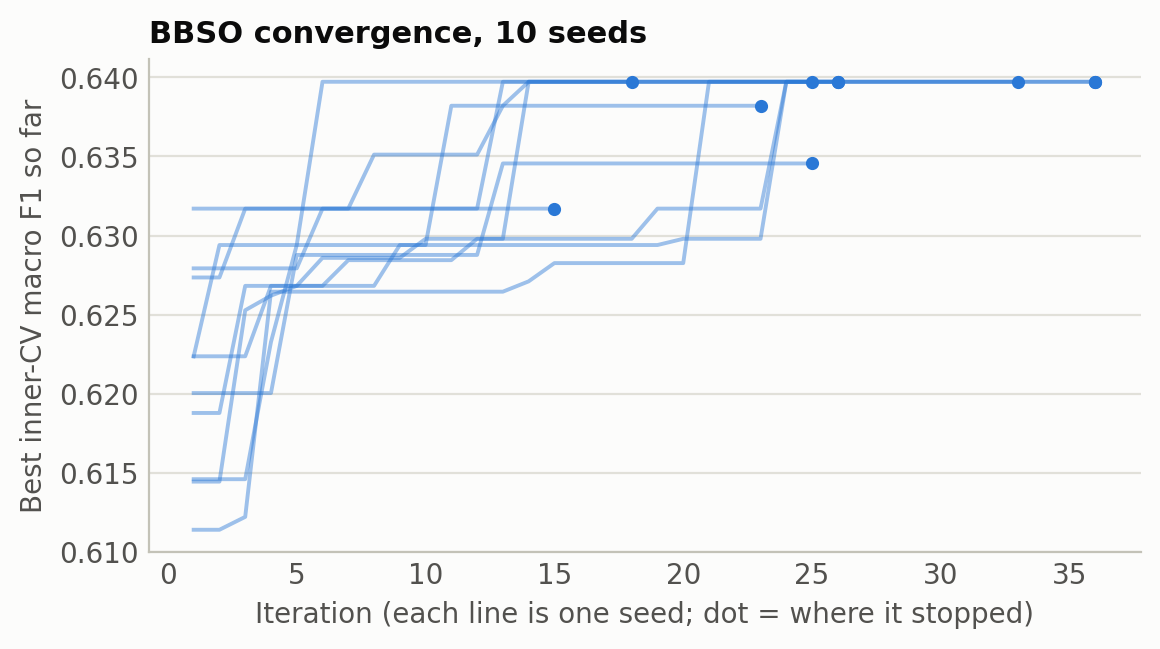

In [3]:
Image("../figures/03_convergence.png", width=640)

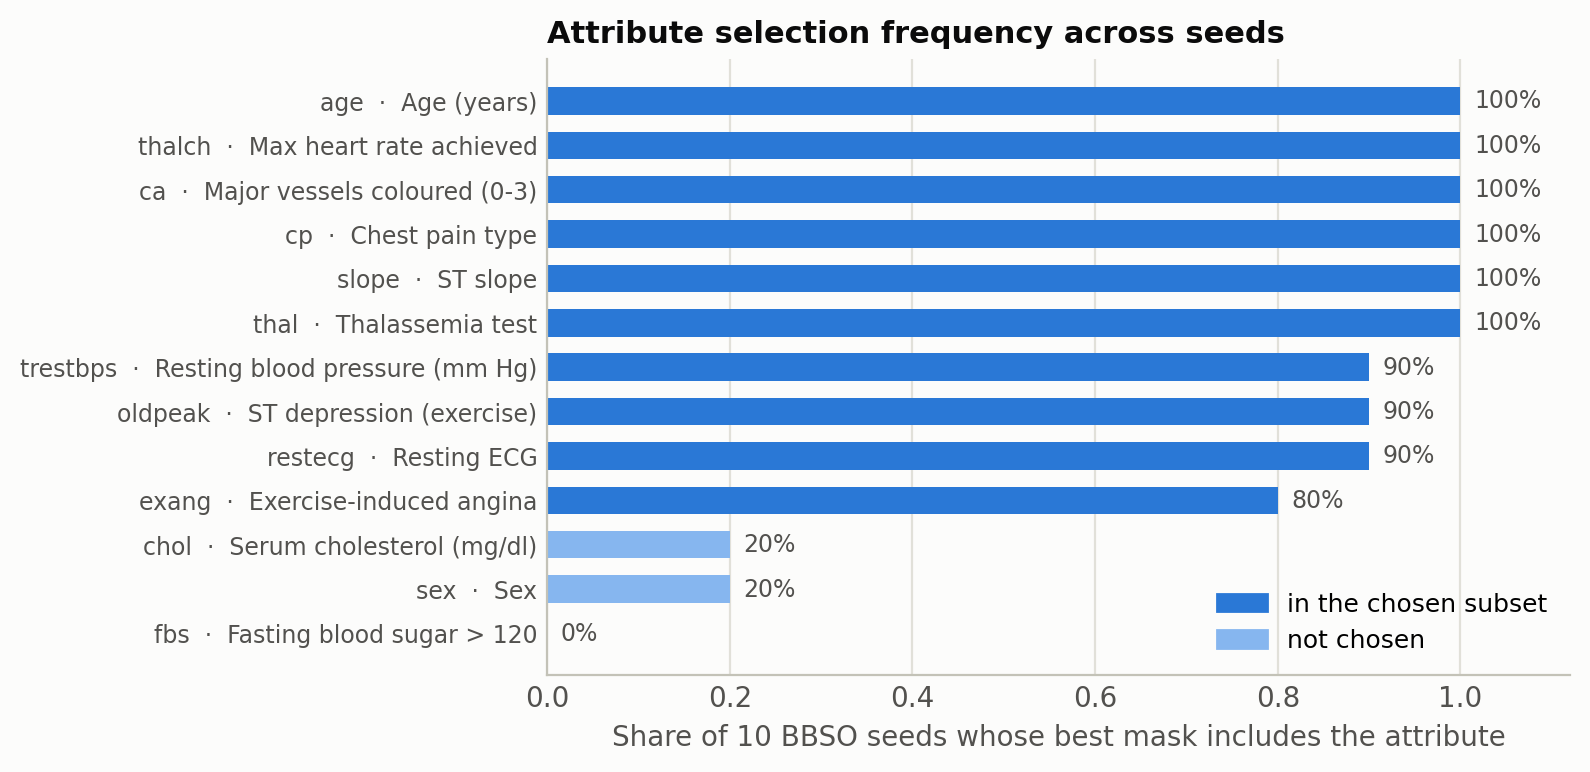

In [4]:
Image("../figures/03_selection_frequency.png", width=660)

Seven of ten seeds converge to the same 10-attribute mask and the other three differ by one or two attributes. Three attributes are dropped by almost every seed: **`fbs`** (never kept), **`sex`** and **`chol`** (kept by two seeds each).

**On `ca`, `thal` and `slope`.** These are the attributes that are mostly missing outside Cleveland (66%, 53% and 34%) and were filled with the training mode/mean. BBSO keeps all three in **every** seed. That is worth stating plainly: after imputation, "`ca` = 0.67" or "`thal` = normal" is partly a code for *which hospital the patient came from*, and the selector finds that signal useful. No missingness indicators were added (they would make the proxy explicit), and the per-hospital diagnostic below is the check on whether that signal generalises.

## 2. Does the subset help under the outer protocol?

The inner-CV fitness rose from 0.614 (all 13) to 0.640 (chosen subset). That number is optimistic by construction: it is the maximum over thousands of masks scored on the same training rows. The honest check is the phase 2 protocol, 5-fold outer CV refitting everything per fold, plus the untouched test split.

In [5]:
cv = pd.read_csv(R + "03_subset_vs_all_cv.csv", header=[0, 1], index_col=[0, 1])
cv["macro_f1"].round(3)

mean    std
model               variant              
logistic_regression all      0.619  0.045
                    subset   0.615  0.052
mlp                 all      0.605  0.040
                    subset   0.585  0.036
random_forest       all      0.629  0.048
                    subset   0.636  0.049

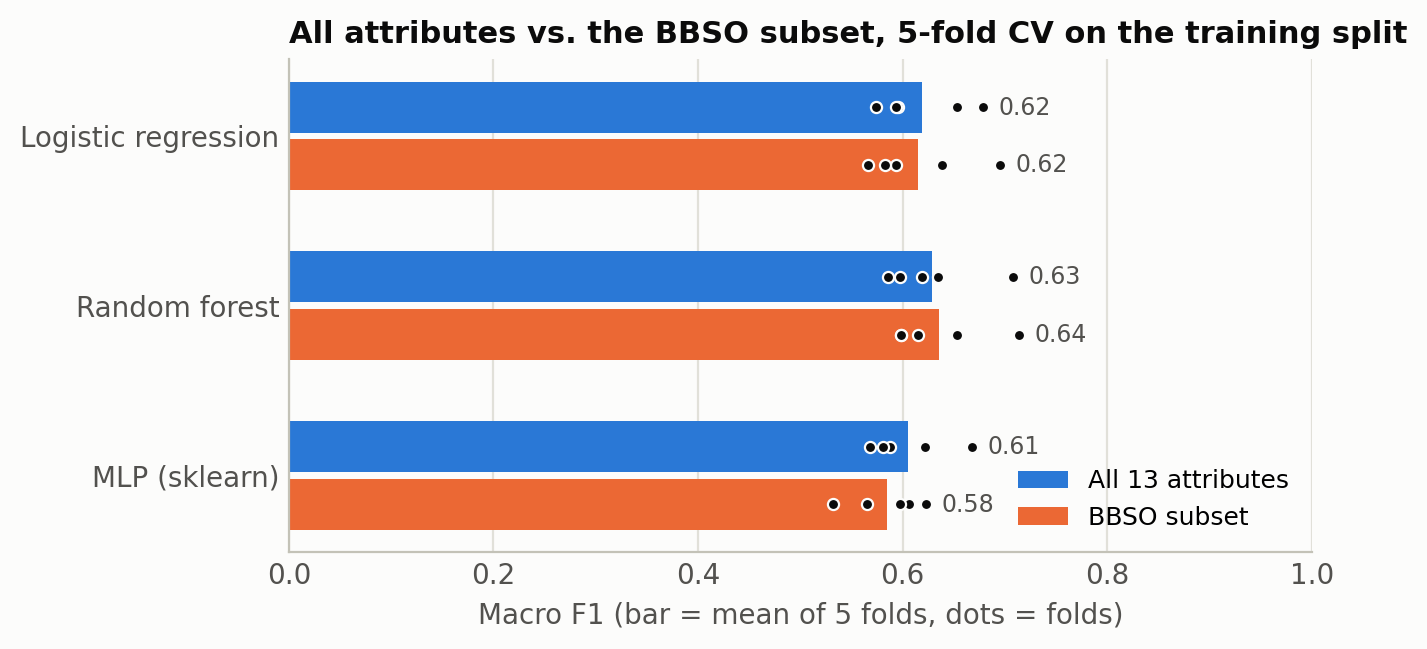

In [6]:
Image("../figures/03_subset_vs_all.png", width=660)

In [7]:
test = pd.read_csv(R + "03_subset_vs_all_test.csv", index_col=[0, 1])
test[["accuracy", "macro_f1", "weighted_f1"]].round(3)

accuracy  macro_f1  weighted_f1
model               variant                                 
logistic_regression all         0.647     0.613        0.644
                    subset      0.630     0.598        0.628
random_forest       all         0.652     0.618        0.644
                    subset      0.630     0.593        0.621
mlp                 all         0.609     0.562        0.595
                    subset      0.614     0.568        0.605

Under the outer CV the subset and the full attribute set are within one fold's standard deviation for all three models (random forest +0.007, logistic regression −0.004, MLP −0.020 macro F1). On the test split the subset is slightly worse for two models and slightly better for the MLP. The inner-CV gain of about 0.025 does not transfer; it is mostly selection optimism.

So the value of BBSO here is not accuracy. It is a **smaller, cleaner input for the fuzzy model**: ten attributes instead of thirteen, with the three least informative ones (`fbs`, `sex`, `chol`, the last of which is missing for every Swiss patient) removed. Fewer attributes means fewer membership functions and fewer rules to read.

## 3. Per-hospital diagnostic for the subset models

In [8]:
site = pd.read_csv(R + "03_per_site_subset.csv")
site.pivot(index="site", columns="model", values="accuracy").round(3)

model,logistic_regression,mlp,random_forest
site,,,
Cleveland,0.698,0.698,0.731
Hungary,0.762,0.729,0.779
Switzerland,0.423,0.371,0.433
VA Long Beach,0.535,0.541,0.535


The pattern is the same as in phase 2: Switzerland hardest, Hungary easiest. Dropping `chol` did not change Switzerland (where cholesterol was always imputed anyway).

## Outputs

`results/03_*.csv`, `results/03_runtime.json`, and `figures/03_*.png`.

**Next phase:** hybrid trapezoidal + Gaussian membership functions for the ten selected attributes, with parameters derived from the training data in clinical units (`to_clinical_units`).